In [33]:
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
import numpy as np

In [34]:
# Read the CSV files (original files remain untouched)
train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

# Combine into one dataset
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

# Show subjects BEFORE renaming
print("Subjects before renaming:")
print(full_df["Name"].value_counts(), "\n")

# A subject is recorded multiple times under different names
# Here we are combining this to one subject
name_mapping = {
    "Yvette0": "Yvette",
    "Yvette1": "Yvette"
}

# Apply renaming (in-memory only)
full_df["Name"] = full_df["Name"].replace(name_mapping)

# Show subjects AFTER renaming
print("Subjects after renaming:")
print(full_df["Name"].value_counts())

# Show per-subject, per-action counts
print("Per-subject action distribution:")
subject_action_counts = (
    full_df
    .groupby(["Name", "Action"])
    .size()
    .unstack(fill_value=0)
)

print(subject_action_counts)

# Final shape check
print("\nCombined dataset shape:", full_df.shape)

Subjects before renaming:
Name
Pedro      215
Yvette     150
Haakon      77
Yvette1     59
Yvette0     34
Name: count, dtype: int64 

Subjects after renaming:
Name
Yvette    243
Pedro     215
Haakon     77
Name: count, dtype: int64
Per-subject action distribution:
Action  ChairSpin  Jumping  Squats
Name                              
Haakon         35       16      26
Pedro           0       85     130
Yvette        186       13      44

Combined dataset shape: (535, 26)


In [41]:
# Seperating into training set and test set
# subject with the least datapoints is used for test set

# Count samples per subject
subject_counts = full_df["Name"].value_counts()

# Identify subject with the least data
test_subject = subject_counts.idxmin()
#test_subject = "Pedro"
test_subject_count = subject_counts.min()

print("Samples per subject:")
print(subject_counts, "\n")

print(f"Selected test subject: {test_subject} ({test_subject_count} samples)\n")
#print(f"Selected test subject: {test_subject} \n")

# Split the dataset
train_df_subject = full_df[full_df["Name"] != test_subject].reset_index(drop=True)
test_df_subject = full_df[full_df["Name"] == test_subject].reset_index(drop=True)

print("\nTrain subjects:")
print(train_df_subject["Name"].value_counts())

print("\nTest subject:")
print(test_df_subject["Name"].value_counts())

# Separate features and labels
X_train = train_df_subject.drop(columns=["Action", "Name"])
y_train = train_df_subject["Action"]

X_test = test_df_subject.drop(columns=["Action", "Name"])
y_test = test_df_subject["Action"]

# Sanity checks
print("Train set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("Random row (training):\n")
print("Features:\n")
print(X_train.sample(n=1), "\n")
print("Label:\n")
print(y_train.sample(n=1), "\n")

print("Random  row (test):\n")
print("Features:\n")
print(X_test.sample(n=1))
print("Label:\n")
print(y_test.sample(n=1))


Samples per subject:
Name
Yvette    243
Pedro     215
Haakon     77
Name: count, dtype: int64 

Selected test subject: Haakon (77 samples)


Train subjects:
Name
Yvette    243
Pedro     215
Name: count, dtype: int64

Test subject:
Name
Haakon    77
Name: count, dtype: int64
Train set shape: (458, 24)
Test set shape: (77, 24)
Random row (training):

Features:

     Mean_Acc_X  Mean_Acc_Y  Mean_Acc_Z  Mean_Gyro_X  Mean_Gyro_Y  \
345    2.696532   -6.447221   -6.608019     0.640996     0.676044   

     Mean_Gyro_Z  Std_Acc_X  Std_Acc_Y  Std_Acc_Z  Std_Gyro_X  ...  Min_Acc_Z  \
345    -0.025696   1.314131   1.137149   2.704627    0.398196  ...  -9.807582   

     Min_Gyro_X  Min_Gyro_Y  Min_Gyro_Z  Max_Acc_X  Max_Acc_Y  Max_Acc_Z  \
345   -0.344528   -0.445779   -0.186161   5.456832  -4.988437  -1.044467   

     Max_Gyro_X  Max_Gyro_Y  Max_Gyro_Z  
345    1.030834    1.597411    0.269544  

[1 rows x 24 columns] 

Label:

87    Jumping
Name: Action, dtype: object 

Random  row (test):

F

In [42]:
# Seperate out the labels from the dataset

# Encoding the label text to label values
label_map = {
    "ChairSpin" : 0,
    "Jumping"   : 1,
    "Squats"    : 2
}

labels_train_int    = train_df_subject["Action"].map(label_map)
labels_test_int     = test_df_subject["Action"].map(label_map)

# Safety check
if labels_train_int.isnull().any() or labels_test_int.isnull().any():
    raise ValueError('Invalid "Action" label detected')

num_classes = len(label_map) # Number of activities we are discerning
labels_train = tf.keras.utils.to_categorical(labels_train_int, num_classes=num_classes)
labels_test  = tf.keras.utils.to_categorical(labels_test_int,  num_classes=num_classes)

In [43]:
# Scaling features

scaler = StandardScaler()
features_train = scaler.fit_transform(X_train)
features_test  = scaler.transform(X_test)

In [44]:
# Defining basic model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(features_train.shape[1],)),    # Arbitrary AI-generated model structure
    Dense(64, activation="relu"),               # Not optimized, but works as a proof-of-concept
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,779 (14.76 KB)

 Trainable params: 3,779 (14.76 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
# Training the model

NUM_EPOCHS = 100
BATCH_SIZE = 16
VALIDATION_SPLIT = 0.2 
RANDOM_SEED = 42

# Early stopping and callback functionality
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    features_train,
    labels_train,
    epochs=NUM_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6612 - loss: 0.8627 - val_accuracy: 0.9674 - val_loss: 0.5775
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9781 - loss: 0.4266 - val_accuracy: 0.9674 - val_loss: 0.3276
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9699 - loss: 0.2405 - val_accuracy: 0.9565 - val_loss: 0.1896
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9699 - loss: 0.1391 - val_accuracy: 0.9565 - val_loss: 0.1220
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9754 - loss: 0.0905 - val_accuracy: 0.9674 - val_loss: 0.0882
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9809 - loss: 0.0639 - val_accuracy: 0.9783 - val_loss: 0.0668
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9891 - loss: 0.0472 - val_accuracy: 0.9783 - val_loss: 0.0499
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9918 - loss: 0.0351 - val_accuracy: 1.0000 - 

1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/stepWARNING:tensorflow:5 out of the last 18 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000001C4160DAA20> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

Confusion Matrix:
[[ 0  0 35]
 [ 0 16  0]
 [ 0  0 26]]

Classification Report:
              precision    recall  f1-score   support

   ChairSpin       0.00      0.00      0.00        35
     Jump

C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classif

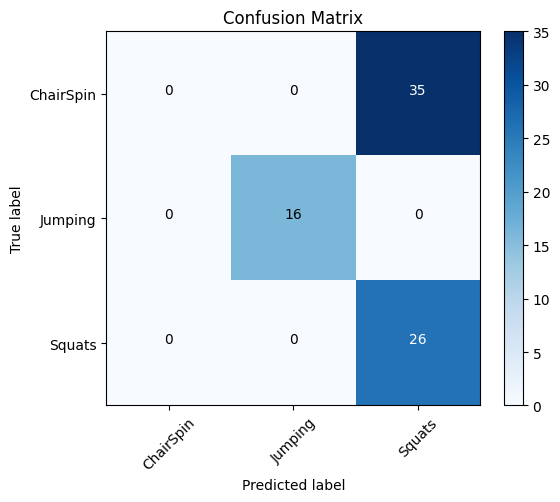

In [46]:
# =========================
# Detailed evaluation
# =========================
from sklearn.metrics import confusion_matrix, classification_report
labels_pred = model.predict(features_test).argmax(axis=1)
labels_true = labels_test.argmax(axis=1)

print("\nConfusion Matrix:")
print(confusion_matrix(labels_true, labels_pred))

print("\nClassification Report:")
print(classification_report(labels_true, labels_pred, target_names=label_map.keys()))

# Make nicer graphic with maptplotlib
import matplotlib.pyplot as plt

cm = confusion_matrix(labels_true, labels_pred)

class_names = list(label_map.keys())

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45)
plt.yticks(tick_marks, class_names)

# Annotate each cell
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black"
        )

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()
